In [99]:
%matplotlib inline 

import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as td
import torchvision as tv
from torch.utils import data
import torchvision.transforms as transforms

from torchvision.transforms import v2

from torchinfo import summary

from PIL import Image
import matplotlib.pyplot as plt
import nntools as nt
import time

import glob



In [100]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [101]:
# dataset_root_dir = 'H:/RGZN/images/orig_images'
dataset_root_dir = 'H:\\DL_DATA\\image_ku1'
file_index = 3

In [ ]:
class NoisyBSDSDataset(td.Dataset):

    def __init__(self, root_dir,mode='train',image_size=(160, 512), sigma=30):
        super(NoisyBSDSDataset, self).__init__()
        self.mode = mode
        self.image_size = image_size
        self.sigma = sigma
        self.images_dir = root_dir
        all_files = os.listdir(self.images_dir)
        self.files = [f for f in all_files if f.endswith('t.pgm')]

    def __len__(self):
        return len(self.files)

    def __repr__(self):
        return "NoisyBSDSDataset(mode={}, image_size={}, sigma={})". \
            format(self.mode, self.image_size, self.sigma)

    def __getitem__(self, idx):
        target_file = self.files[idx]
        prefix = target_file[:-5]
        noisy_file = prefix + 'n.pgm'
        
        target_path = os.path.join(self.images_dir, target_file)
        noisy_path = os.path.join(self.images_dir, noisy_file)
        
        clean = Image.open(target_path).convert('L')
        noisy_img = Image.open(noisy_path).convert('L')
        
        # transform = tv.transforms.Compose([
        #     tv.transforms.Resize(self.image_size),
        #     tv.transforms.ToTensor(),
        #     tv.transforms.Normalize(.5, .5)
        #     ])
            
        # clean = transform(clean)
        # noisy_img = transform(noisy_img)
    

        transform_p = tv.transforms.Compose([
            tv.transforms.Resize(self.image_size),
            tv.transforms.ToTensor(),          # 得到 [0,1] 的 float Tensor
            tv.transforms.Normalize(.5, .5)
        ])
        clean = transform_p(clean)
        noisy_img = transform_p(noisy_img)

        stacked = torch.stack([clean, noisy_img], dim=0) 

        geo_transform = v2.Compose([
            v2.RandomHorizontalFlip(p=0.5),
            v2.RandomVerticalFlip(p=0.2),
            v2.RandomRotation(degrees=10, fill=-1),  
        ])
        stacked = geo_transform(stacked) 
        clean = stacked[0]
        noisy_img = stacked[1]


        return clean, noisy_img

In [103]:
def myimshow(image, ax=plt):
    image = image.to('cpu').numpy()
    image = np.moveaxis(image, [0, 1, 2], [2, 0, 1])
    image = (image + 1) / 2
    image[image < 0] = 0
    image[image > 1] = 1
    h = ax.imshow(image,cmap='gray')
    ax.axis('off')
    return h

In [104]:
train_set = NoisyBSDSDataset(dataset_root_dir, mode='train', image_size=(480, 640), sigma=30)
test_set = NoisyBSDSDataset(dataset_root_dir, mode='test', image_size=(480, 640), sigma=30)

# Once you have a despeckled reference (e.g. `pre_img/proc_images` or a stronger
# NLM/BM3D/SRAD output), point the training target at it so the network learns to
# remove real speckle instead of reproducing it:
# train_set = NoisyBSDSDataset(dataset_root_dir, mode='train', sigma=30,
#                              target_dir=r'H:\RGZN\images\pre_img\proc_images')

image size is torch.Size([1, 480, 640]).


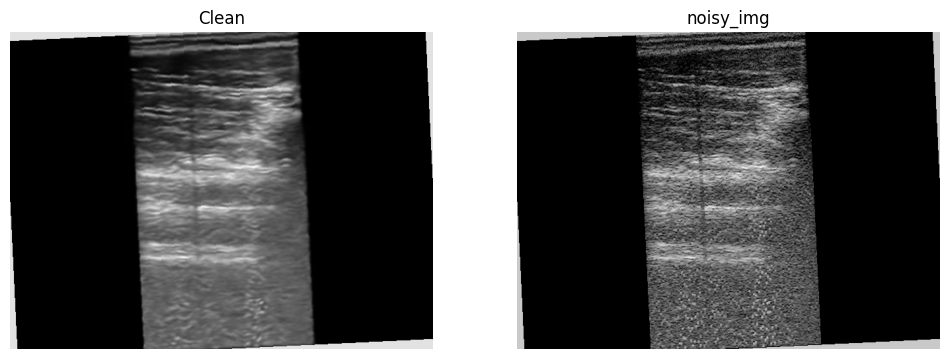

In [105]:
x = test_set[12]
fig, axes = plt.subplots(ncols=2, figsize=(12, 6))
myimshow(x[0], ax=axes[0])
axes[0].set_title('Clean')
myimshow(x[1], ax=axes[1])
axes[1].set_title('noisy_img')

print(f'image size is {x[0].shape}.')

In [106]:
class DenoisLoss(nn.Module):
    """Composite loss targeting the three goals:
       - smooth without blurring  -> Charbonnier + small TV term
       - darker dark regions      -> soft dark mask + asymmetric penalty
       - crisper boundaries       -> edge-weighted loss (+ optional SSIM)
    """

    def __init__(self, edge_w=2.0, tv_w=1e-4, dark_thr=-0.2, dark_tau=0.1,
                 dark_w=1.0, ssim_w=0.1, eps=1e-3):
        super().__init__()
        self.edge_w = edge_w
        self.tv_w = tv_w
        self.dark_thr = dark_thr
        self.dark_tau = dark_tau
        self.dark_w = dark_w
        self.ssim_w = ssim_w
        self.eps = eps

    def _sobel(self, x):
        kx = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
                          dtype=x.dtype, device=x.device).view(1, 1, 3, 3)
        ky = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
                          dtype=x.dtype, device=x.device).view(1, 1, 3, 3)
        return F.conv2d(x, kx, padding=1), F.conv2d(x, ky, padding=1)

    def _ssim(self, y, d, win=11, C1=0.01 ** 2, C2=0.03 ** 2):
        y = (y + 1) / 2
        d = (d + 1) / 2
        mu_y = F.avg_pool2d(y, win, 1)
        mu_d = F.avg_pool2d(d, win, 1)
        mu_yd = mu_y * mu_d
        mu_y2, mu_d2 = mu_y ** 2, mu_d ** 2
        sig_y2 = F.avg_pool2d(y * y, win, 1) - mu_y2
        sig_d2 = F.avg_pool2d(d * d, win, 1) - mu_d2
        sig_yd = F.avg_pool2d(y * d, win, 1) - mu_yd
        ssim = ((2 * mu_yd + C1) * (2 * sig_yd + C2)) / \
               ((mu_y2 + mu_d2 + C1) * (sig_y2 + sig_d2 + C2))
        return ssim.mean()

    def forward(self, y, d):
        diff = y - d

        # 1) base reconstruction (edge-preserving, less blur than MSE)
        base = torch.sqrt(diff ** 2 + self.eps ** 2).mean()

        # 2) edge-weighted: larger weight where the target has strong gradients
        gx, gy = self._sobel(d)
        g = torch.sqrt(gx ** 2 + gy ** 2)
        w_edge = 1.0 + self.edge_w * (g / (g.max() + 1e-8))
        edge_loss = (w_edge * (diff ** 2)).mean()

        # 3) dark regions: soft mask + asymmetric penalty for over-bright output
        mask = torch.sigmoid((self.dark_thr - d) / self.dark_tau)
        dark_loss = (mask * (diff ** 2)).mean()
        over = torch.clamp(diff, min=0)
        asym_loss = (mask * (over ** 2)).mean()

        # 4) total variation: smooth output while keeping strong edges
        tv = (torch.abs(y[..., 1:, :] - y[..., :-1, :]).mean()
              + torch.abs(y[..., :, 1:] - y[..., :, :-1]).mean())

        loss = (base
                + self.edge_w * edge_loss
                + self.dark_w * (dark_loss + asym_loss)
                + self.tv_w * tv)

        if self.ssim_w > 0:
            loss = loss + self.ssim_w * (1.0 - self._ssim(y, d))
        return loss


class NNRegressor(nt.NeuralNetwork):

    def __init__(self):
        super(NNRegressor, self).__init__()
        # Composite loss replaces plain MSE to meet the three goals.
        self.fn_loss = DenoisLoss(edge_w=2.0, tv_w=1e-4, dark_thr=-0.2,
                                  dark_tau=0.1, dark_w=1.0, ssim_w=0.1)
        # self.fn_loss = DenoisLoss(edge_w=1.0, tv_w=0.05, dark_thr=-0.8,
        #                           dark_tau=0.1, dark_w=1.0, ssim_w=0.1)
    def criterion(self, y, d):
        return self.fn_loss(y, d)

In [107]:
class DenoisingStatsManager(nt.StatsManager):

    def __init__(self):
        super(DenoisingStatsManager, self).__init__()

    def init(self):
        super(DenoisingStatsManager, self).init()
        self.running_psnr = 0
        self.running_ssim = 0
        self.running_dark_mse = 0
        self.running_edge_grad = 0

    def _ssim(self, y, d, win=11, C1=0.01 ** 2, C2=0.03 ** 2):
        y = (y + 1) / 2
        d = (d + 1) / 2
        mu_y = F.avg_pool2d(y, win, 1)
        mu_d = F.avg_pool2d(d, win, 1)
        mu_yd = mu_y * mu_d
        mu_y2, mu_d2 = mu_y ** 2, mu_d ** 2
        sig_y2 = F.avg_pool2d(y * y, win, 1) - mu_y2
        sig_d2 = F.avg_pool2d(d * d, win, 1) - mu_d2
        sig_yd = F.avg_pool2d(y * d, win, 1) - mu_yd
        ssim = ((2 * mu_yd + C1) * (2 * sig_yd + C2)) / \
               ((mu_y2 + mu_d2 + C1) * (sig_y2 + sig_d2 + C2))
        return ssim.mean()

    def accumulate(self, loss, x, y, d):
        super(DenoisingStatsManager, self).accumulate(loss, x, y, d)
        n = x.shape[0] * x.shape[1] * x.shape[2] * x.shape[3]
        self.running_psnr += 10 * torch.log10(4 * n / (torch.norm(y - d) ** 2))
        self.running_ssim += self._ssim(y, d)

        # dark-region reconstruction error (target pixels darker than -0.2)
        mask = (d < -0.2).float()
        self.running_dark_mse += (((y - d) ** 2) * mask).sum() / (mask.sum() + 1e-8)

        # mean gradient magnitude of the output (edge sharpness)
        kx = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
                          dtype=y.dtype, device=y.device).view(1, 1, 3, 3)
        ky = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
                          dtype=y.dtype, device=y.device).view(1, 1, 3, 3)
        gx = F.conv2d(y, kx, padding=1)
        gy = F.conv2d(y, ky, padding=1)
        self.running_edge_grad += torch.sqrt(gx ** 2 + gy ** 2).mean()

    def summarize(self):
        loss = super(DenoisingStatsManager, self).summarize()
        return {'loss': loss,
                'PSNR': (self.running_psnr / self.number_update).cpu(),
                'SSIM': (self.running_ssim / self.number_update).cpu(),
                'dark_mse': (self.running_dark_mse / self.number_update).cpu(),
                'edge_grad': (self.running_edge_grad / self.number_update).cpu()}

In [108]:
def plot(exp, fig, axes, noisy, visu_rate=2):
    if exp.epoch % visu_rate != 0:
        return
    with torch.no_grad():
        denoised = exp.net(noisy[None].to(net.device))[0]
    axes[0][0].clear()
    axes[0][1].clear()
    axes[1][0].clear()
    axes[1][1].clear()
    myimshow(noisy, ax=axes[0][0])
    axes[0][0].set_title('Noisy image')
    
    myimshow(denoised, ax=axes[0][1])
    axes[0][1].set_title('Denoised image')
    
    axes[1][0].plot([exp.history[k][0]['loss'] for k in range(exp.epoch)], label='training loss')
    axes[1][0].set_ylabel('Loss')
    axes[1][0].set_xlabel('Epoch')
    axes[1][0].legend()
    
    axes[1][1].plot([exp.history[k][0]['PSNR'] for k in range(exp.epoch)], label='training psnr')
    axes[1][1].set_ylabel('PSNR')
    axes[1][1].set_xlabel('Epoch')
    axes[1][1].legend()
    
    plt.tight_layout()
    fig.canvas.draw()

In [109]:
class Denois(NNRegressor):
    def __init__(self, D, C=32, residual=True):
        super(Denois, self).__init__()
        self.D = D
        self.residual = residual

        # convolution layers
        self.conv = nn.ModuleList()
        self.conv.append(nn.Conv2d(1, C, 3, padding=1))
        for i in range(D):
            if i < D//2 - 1:
                self.conv.append(nn.Conv2d(C, C, 3, padding=1, stride=2))
            elif i >= D//2 + 1:
                # replace ConvTranspose2d with standard conv; upsampling will be done via F.interpolate in forward
                self.conv.append(nn.Conv2d(C, C, 3, padding=1, stride=1))
            else:
                self.conv.append(nn.Conv2d(C, C, 3, padding=1, stride=1))

        self.conv.append(nn.Conv2d(C, 1, 3, padding=1))
        for i in range(len(self.conv[:-1])):
            nn.init.kaiming_normal_(self.conv[i].weight.data, nonlinearity='relu')

        # batch normalization
        self.bn = nn.ModuleList()
        self.bn.extend([nn.BatchNorm2d(C, C) for _ in range(D)])
        for i in range(D):
            nn.init.constant_(self.bn[i].weight.data, 1.25 * np.sqrt(C))

    def forward(self, x):
        D = self.D
        h = F.relu(self.conv[0](x))
        h_buff = []
        for i in range(D//2-1):
            h = F.relu(self.bn[i](self.conv[i+1](h)))
            h_buff.append(h)
        for i in range(D//2-1, D//2+1):
            h = F.relu(self.bn[i](self.conv[i+1](h)))
        for i in range(D//2+1, D):
            j = i - (D//2 + 1) + 1
            # sum at current resolution then upsample by 2x to mimic ConvTranspose2d(stride=2)
            h = (h + h_buff[-j]) / np.sqrt(2)
            h = F.interpolate(h, scale_factor=2, mode='nearest')
            h = F.relu(self.bn[i](self.conv[i+1](h)))
        y = self.conv[D+1](h)
        if self.residual:
            y = x - y
        return y

In [110]:
save_file_name = f"../checkpoints/denois_{file_index}"
save_file_name

'../checkpoints/denois_3'

In [111]:
torch.manual_seed(0)
np.random.seed(0)

lr = 1e-3
net = Denois(6, residual=True).to(device)
adam = torch.optim.Adam(net.parameters(), lr=lr)
stats_manager = DenoisingStatsManager()
exp2 = nt.Experiment(net, train_set, test_set, adam, stats_manager, batch_size=4,
               output_dir=save_file_name, perform_validation_during_training=True)

In [112]:
# fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(9, 7))
exp2.run(num_epochs=200)

Start/Continue training from epoch 0


KeyboardInterrupt: 

In [ ]:
model = exp2.net.to(device)
# model = model.half()
model.eval()

# save_path = "H:\\tmp_work\\rk3576_test_yy\\app\\src\\main\\assets"
example = torch.rand(1, 1,480, 640).to(device)

output = model(example)

# onnx_file_name = "model_480_640.onnx"
onnx_file_name=f"model_480_640_{file_index}.onnx"

# 导出模型
torch.onnx.export(model,        # 模型的名称
                  example,   # 一组实例化输入
                  onnx_file_name,   # 文件保存路径/名称
                  export_params=True,        #  如果指定为True或默认, 参数也会被导出. 如果你要导出一个没训练过的就设为 False.
                  do_constant_folding=True,  # 是否执行常量折叠优化
                  input_names = ['input'],   # 输入模型的张量的名称
                  output_names = ['output'], # 输出模型的张量的名称
                  opset_version=18
)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu118 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



In [ ]:
test_path = glob.glob('H:\\RGZN\\images\\test\\*.*')

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((480,640)),
    transforms.Normalize(0.5,0.5)]
)

class AO_dataset(data.Dataset):
    def __init__(self,imgs_path):
        self.imgs_path = imgs_path
    def __getitem__(self, index):
        img_path = self.imgs_path[index]
        img = Image.open(img_path).convert("L") #灰度
        img = transform(img)
        return img
    
    def __len__(self):
        return len(self.imgs_path)
    
test_ds = AO_dataset(test_path)

x = test_ds[0]
x = x.unsqueeze(0).to(device)

In [ ]:
def myimshow2(image, ax=plt):
    image = (image + 1) / 2
    image[image < 0] = 0
    image[image > 1] = 1
    h = ax.imshow(image,cmap='gray')
    ax.axis('off')
    return h



In [ ]:
import onnxruntime as ort

model = ort.InferenceSession(onnx_file_name)
img = []
img_old = []
for i in range(len(test_ds)):
    x = test_ds[i].unsqueeze(0)  # 添加batch维度 [1, 1, 480, 640]
    input_data = x.numpy()
    img_old.append(test_ds[i].squeeze())
    output = model.run(None, {'input': input_data})[0]
    img.append(output[0].squeeze())
    
fig, axes = plt.subplots(ncols=2,nrows=len(test_ds), figsize=(15,150), sharex='all', sharey='all')
for i in range(len(test_ds)):
    myimshow2(img[i], ax=axes[i,0])
    myimshow2(img_old[i], ax=axes[i,1])
    
    